In [1]:
import cv2
import matplotlib.pyplot as plt
import numpy as np
from sklearn.cluster import KMeans

In [3]:
from tqdm import tqdm
from ultralytics import YOLO
import supervision as sv

SOURCE_VIDEO_PATH = "../input_videos/goalkeeper.mp4"
PLAYER_ID = 4
STRIDE = 3
model = YOLO("../models/best_new.pt")

frame_generator = sv.get_video_frames_generator(
    source_path=SOURCE_VIDEO_PATH, stride=STRIDE)


crops = []
for frame in tqdm(frame_generator, desc='collecting crops'):
    result = model.predict(frame, conf=0.3)[0]
    detections = sv.Detections.from_ultralytics(result)
    detections = detections.with_nms(threshold=0.5, class_agnostic=True)
    detections = detections[detections.class_id == PLAYER_ID]
    # players_crops = [sv.crop_image(frame, xyxy) for xyxy in detections.xyxy]
    # crops += players_crops
    for xyxy in detections.xyxy:
        full_crop = sv.crop_image(frame, xyxy)
        height = full_crop.shape[0]
        top_half = full_crop[int(height*0.15):int(height*0.6)]  # keep top half
        crops.append(top_half)

collecting crops: 0it [00:00, ?it/s]


0: 384x640 1 goalkeeper, 1 goalpost, 8 players, 1 playername, 997.7ms
Speed: 4.0ms preprocess, 997.7ms inference, 2.0ms postprocess per image at shape (1, 3, 384, 640)


collecting crops: 1it [00:04,  4.92s/it]


0: 384x640 1 goalpost, 9 players, 1 playername, 921.3ms
Speed: 5.9ms preprocess, 921.3ms inference, 1.4ms postprocess per image at shape (1, 3, 384, 640)


collecting crops: 2it [00:05,  2.59s/it]

...

collecting crops: 29it [00:31,  1.03it/s]


0: 384x640 2 goalkeepers, 1 goalpost, 7 players, 1 playername, 1 referee, 937.1ms
Speed: 3.4ms preprocess, 937.1ms inference, 1.3ms postprocess per image at shape (1, 3, 384, 640)


collecting crops: 30it [00:32,  1.03it/s]


0: 384x640 1 goalkeeper, 1 goalpost, 6 players, 1 playername, 1 referee, 910.6ms
Speed: 3.8ms preprocess, 910.6ms inference, 1.3ms postprocess per image at shape (1, 3, 384, 640)


collecting crops: 31it [00:33,  1.07s/it]


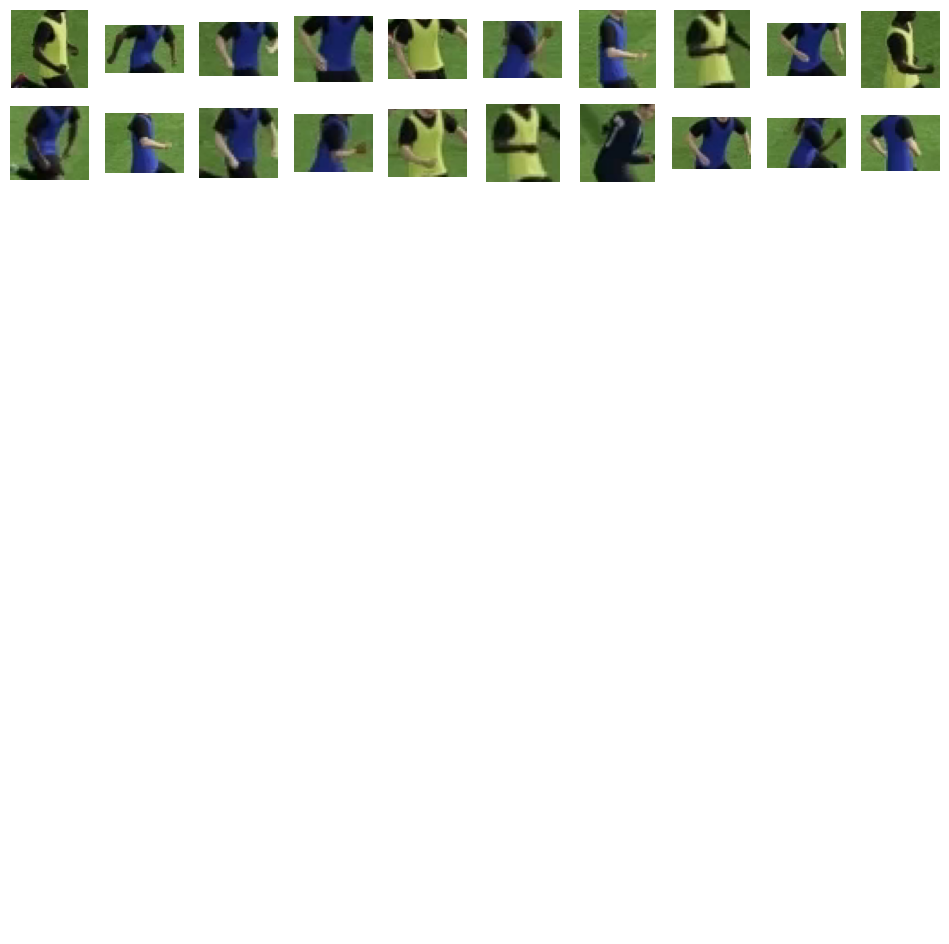

261


In [4]:
sv.plot_images_grid(crops[:20], grid_size=(10, 10))
print(len(crops))

In [5]:
import torch
from transformers import AutoProcessor, SiglipVisionModel

SIGLIP_MODEL_PATH = 'google/siglip-base-patch16-224'

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print(DEVICE)
EMBEDDINGS_MODEL = SiglipVisionModel.from_pretrained(SIGLIP_MODEL_PATH).to(DEVICE)
EMBEDDINGS_PROCESSOR = AutoProcessor.from_pretrained(SIGLIP_MODEL_PATH)

cpu


Using a slow image processor as `use_fast` is unset and a slow processor was saved with this model. `use_fast=True` will be the default behavior in v4.52, even if the model was saved with a slow processor. This will result in minor differences in outputs. You'll still be able to use a slow processor with `use_fast=False`.


In [6]:
import numpy as np
from more_itertools import chunked

BATCH_SIZE = 32

crop_pillow = [sv.cv2_to_pillow(crop) for crop in crops]
batches = chunked(crop_pillow, BATCH_SIZE)
data = []
with torch.no_grad():
    for batch in tqdm(batches, desc='embedding extraction'):
        inputs = EMBEDDINGS_PROCESSOR(images=batch, return_tensors="pt").to(DEVICE)
        outputs = EMBEDDINGS_MODEL(**inputs)
        embeddings = torch.mean(outputs.last_hidden_state, dim=1).cpu().numpy()
        data.append(embeddings)

data = np.concatenate(data)
# initial_data = data


embedding extraction: 9it [01:05,  7.26s/it]


In [7]:
import umap
from sklearn.cluster import KMeans

REDUCER = umap.UMAP(n_components=3)
REDUCER.fit(data)  # initial_data is shape (470, 768)

CLUSTERING_MODEL = KMeans(n_clusters=2)
initial_projection = REDUCER.transform(data)
CLUSTERING_MODEL.fit(initial_projection)

KMeans(n_clusters=2)

In [9]:
clusters = CLUSTERING_MODEL.predict(initial_projection)

In [14]:
import joblib

# Save KMeans model
joblib.dump(CLUSTERING_MODEL, "../models/kmeans_trained_final.pkl")

# Save UMAP reducer (optional, if you also want to save the reducer)
# joblib.dump(projections, "projections_model.pkl")
joblib.dump(REDUCER, "../models/reducer_model_final.pkl")

['../models/reducer_model_final.pkl']

[1 0 0 0 1 0 0 1 0 1]
81


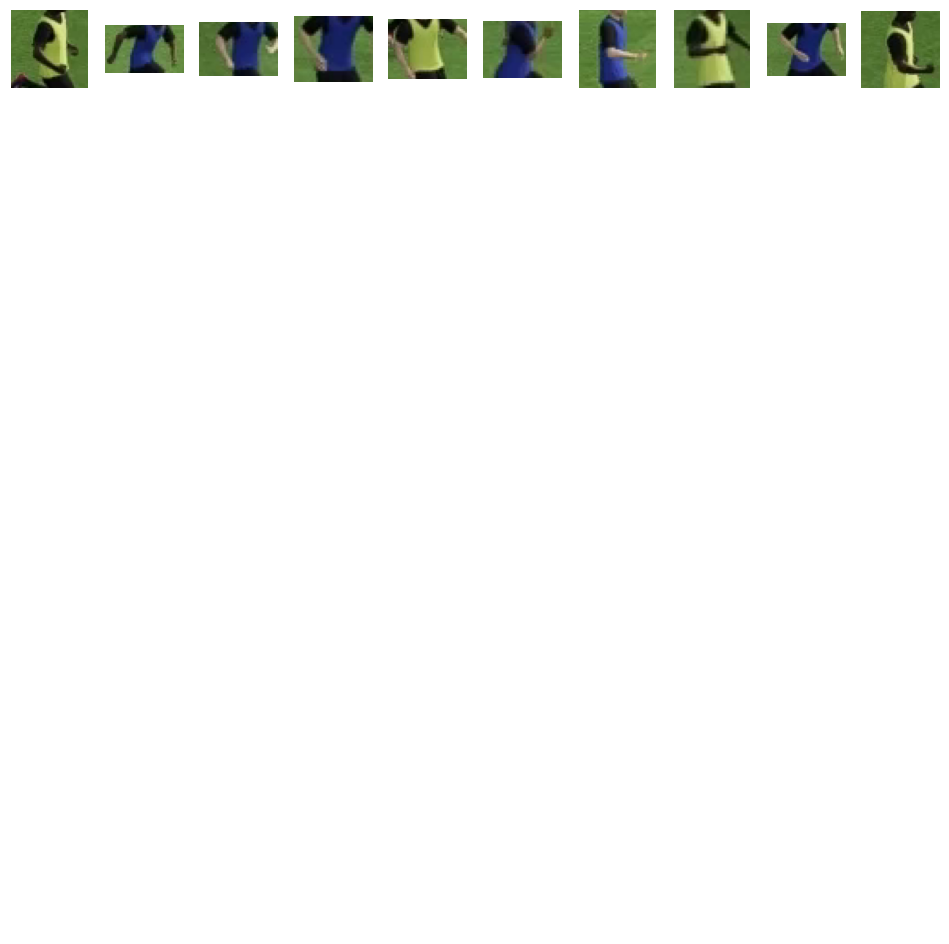

In [12]:
print(clusters[:10])
team_0 = [crop for crop, cluster in zip(crops, clusters)]
team_1 = [crop for crop, cluster in zip(crops, clusters) if cluster == 1]
print(len(team_1))
sv.plot_images_grid(team_0[:10], grid_size=(10, 10))

FATTT

In [157]:

image_path = "C:/Users/DELL/Pictures/Screenshots/barca2.png"
image = cv2.imread(image_path)
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

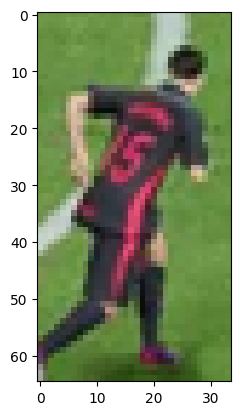

In [158]:
plt.imshow(image)
plt.show()

# take the top half of the image

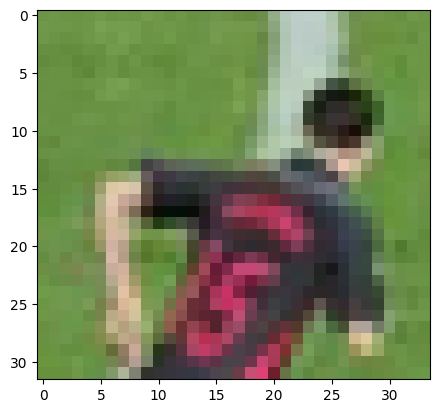

In [159]:
top_half_image=  image[0: int(image.shape[0]/2), :]

plt.imshow(top_half_image)
plt.show()

# Cluster the image into two clusters

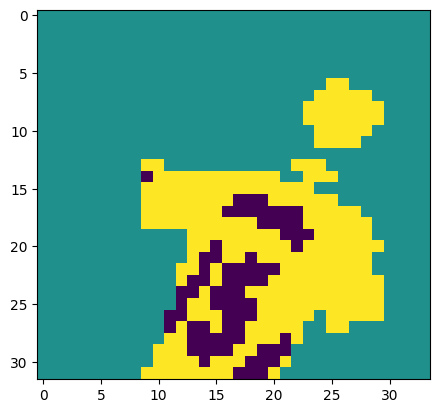

In [160]:
# Reshape the image into 2d array
image_2d = top_half_image.reshape(-1, 3)

# perform k-means clustering with 2 clusters
kmeans = KMeans(n_clusters=3, random_state=0)
kmeans.fit(image_2d)

# get the cluster labels
labels = kmeans.labels_

# reshape the labels into the orginal image shape
clustered_image = labels.reshape(top_half_image.shape[0], top_half_image.shape[1])

# Display the clustered image
plt.imshow(clustered_image)
plt.show()

In [ ]:
corner_clusters = [clustered_image[0, 0], clustered_image[0, -1], clustered_image[-1, 0], clustered_image[-1, -1]]
non_player_cluster = max(set(corner_clusters), key=corner_clusters.count)
#print(non_player_cluster)

0


In [ ]:
player_cluster = 1-non_player_cluster
#print(player_cluster)

1


[63.10162602 55.03658537 53.70325203]


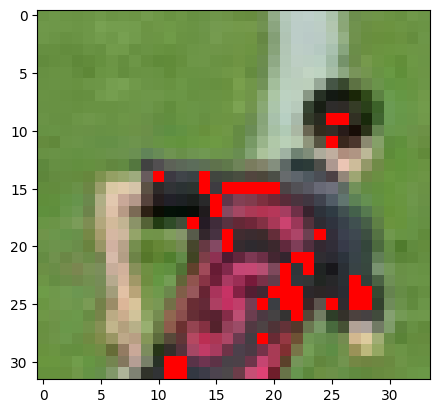

In [163]:
playerColor = kmeans.cluster_centers_[player_cluster]
print(playerColor)
# Create a mask for the player color
player_mask = cv2.inRange(top_half_image, playerColor - 10, playerColor + 10)

# Create an output image to display the player color
output_image = top_half_image.copy()
output_image[player_mask > 0] = [255, 0, 0]  # Color the player pixels in red

# Display the output image
plt.imshow(output_image)
plt.show()

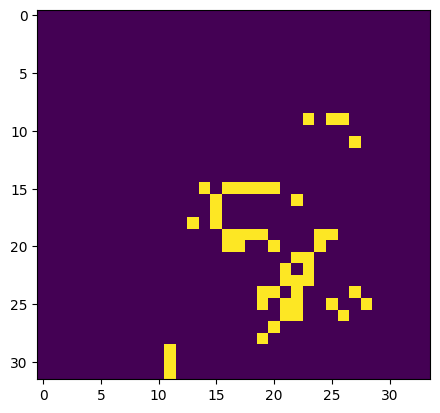

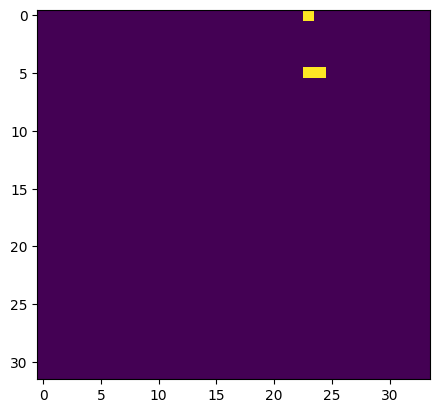

49 3
The team of the image is: Barca


In [164]:
# # barca colors
# # [63.51434426, 46.79918033, 47.5307377 ]
# # [75.74074074, 55.53872054, 58.18518519]
# # array([54.1350211 , 52.38396624, 48.40084388])
# # [65.2421875  49.83203125 49.16796875]

# # barca color range
# lower_barca_color = np.array([50 , 40, 42])
# upper_barca_color = np.array([80, 60, 62])


# # madrid colors 
# # [222.96164384 223.42739726 222.54246575]
# # [212.2674772  215.71732523 216.12765957]
# # [193.12844037 198.15902141 193.81651376]
# # [201.75535168 206.36697248 207.44648318]

# lower_madrid_color = np.array([190, 190, 190])
# upper_madrid_color = np.array([230, 230, 230])

# # Create a mask for the barca colors
# barca_mask = cv2.inRange(top_half_image, lower_barca_color, upper_barca_color)

# # Create a mask for the madrid colors
# madrid_mask = cv2.inRange(top_half_image, lower_madrid_color, upper_madrid_color)

# # Assign team based on the masks
# team_assignmentB = np.zeros(clustered_image.shape, dtype=np.uint8)
# team_assignmentM = np.zeros(clustered_image.shape, dtype=np.uint8)
# team_assignmentB[barca_mask > 0] = 1  # Barca team
# team_assignmentM[madrid_mask > 0] = 2  # Madrid team

# plt.imshow(barca_mask, cmap='viridis')
# plt.show()
# plt.imshow(team_assignmentM, cmap='viridis')
# plt.show()
# # Determine the team with the maximum in-range color
# barca_count = np.sum(barca_mask > 0)
# madrid_count = np.sum(madrid_mask > 0)
# print(barca_count, madrid_count)

# if barca_count > madrid_count:
#     team = "Barca"
# else:
#     team = "Madrid"

# print(f"The team of the image is: {team}")

Average color for the cluster with max assignees: [82.72647059 61.37647059 62.74411765]


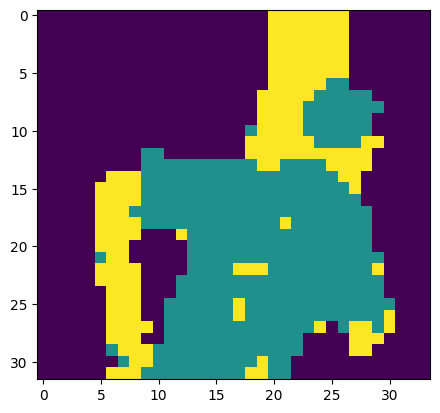

In [166]:
# import cv2
# import matplotlib.pyplot as plt
# import numpy as np
# from sklearn.cluster import KMeans

# # Load the image
# image_path = "C:/Users/DELL/Pictures/Screenshots/barca2.png"
# image = cv2.imread(image_path)
# image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

# # Take the top half of the image
# top_half_image = image[0: int(image.shape[0] / 2), :]

# # Define the green color range in HSV
# lower_green = np.array([35, 100, 100])
# upper_green = np.array([85, 255, 255])

# # Convert the image to HSV
# hsv_image = cv2.cvtColor(top_half_image, cv2.COLOR_RGB2HSV)

# # Create a mask for the green color
# mask = cv2.inRange(hsv_image, lower_green, upper_green)

# # Invert the mask to get the non-green pixels
# mask_inv = cv2.bitwise_not(mask)

# # Extract the non-green pixels
# non_green_pixels = top_half_image[mask_inv == 255]

# # Perform k-means clustering with 2 clusters on non-green pixels
# kmeans = KMeans(n_clusters=2, random_state=0)
# kmeans.fit(non_green_pixels)

# # Get the cluster labels for non-green pixels
# labels = kmeans.labels_

# # Create an empty array for the clustered image
# clustered_image = np.zeros((top_half_image.shape[0], top_half_image.shape[1]), dtype=np.uint8)

# # Assign the cluster labels to the non-green pixels in the clustered image
# clustered_image[mask_inv == 255] = labels + 1  # Adding 1 to differentiate from the green background


# # Find the cluster with the maximum number of assignees
# max_assignees_cluster = np.argmax(np.bincount(labels))


# # Print the average color for the cluster with the maximum number of assignees
# print(f"Average color for the cluster with max assignees: {kmeans.cluster_centers_[max_assignees_cluster]}")

# # Display the clustered image
# plt.imshow(clustered_image, cmap='viridis')
# plt.show()